In [1]:
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from scipy.linalg import qr, svd, hankel
from tqdm import tqdm

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

No windowing system present. Using surfaceless platform
No config found!
No config found!


Available devices:
✅ (default) | Tesla V100-SXM2-32GB | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 16.0.6, 256 bits) | CPU | Vulkan | Mesa 24.0.0-devel (git-3ca1f35cbf) (LLVM 16.0.6)
❗ | Tesla V100-SXM2-32GB/PCIe/SSE2 | Unknown | OpenGL | 


In [2]:
def generate_data(
    n_timepoints: int, 
    n_components: int, 
    noise: int, 
    n_pixels: int, # n_pixels PER component
    n_pixels_bg
):
    interp_factor = 2
    
    clean = np.zeros((n_components, n_timepoints * interp_factor))
    
    x = 0
    a = 0.7
    
    b = 0
    
    firing_prop = 0.05
    
    spikes = list()
    
    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))
    
    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])
    
        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])
    
    n_timepoints *= 2
    
    # fig = plt.figure(figsize=(17, 1))
    # for i in range(n_components):
    #     plt.plot(clean[i])
    
    n_pixels = 3
    
    series = list()
    
    for i in range(n_components):
        for j in range(n_pixels):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
    
    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])

    return series

In [3]:
class SpaceTimeSVD:
    def __init__(self, movie_vectorized: np.ndarray, w: int):
        self.movie = movie_vectorized
        self.w = w
        self.adjacency = None

    def compute(self):
        print("Computing F, P")
        Ys = list()
        Ps = list()
        Fs = list()

        series = self.movie
        w = self.w

        n_pixels = self.movie.shape[0]
        for i in tqdm(range(n_pixels)):
            y = hankel(series[i, :w], series[i, w:])
            p = np.flipud(y[:int(w / 2)])
            f = y[int(w / 2):]
        
            Ys.append(y)
            Ps.append(p)
            Fs.append(f)

        P_F_shape = (int(w / 2) * n_pixels, movie.shape[1] - w)

        P = np.zeros(P_F_shape)
        F = np.zeros(P_F_shape)
        
        for i in tqdm(range(n_pixels)):
            P[i::n_pixels] = Ps[i]
            F[i::n_pixels] = Fs[i]

        print("computing H")
        H = (F @ P.T) / P.shape[1]

        print("Computing Hp")
        Hp = np.zeros((int(w / 2)**2, n_pixels**2))

        for row_ix, (block_i, block_j) in enumerate(product(*[range(0, int(w / 2) * n_pixels, n_pixels)]*2)):
            Hp[row_ix] = H.T[block_i:block_i + n_pixels, block_j:block_j + n_pixels].ravel()

        del H

        print("computimng svd of Hp")
        u, s, v = svd(Hp)

        del Hp

        self.adjacency = v[0].reshape(self.movie.shape[0], self.movie.shape[0])

In [4]:
class ClusteringCPQR:
    def __init__(self, adjacency: np.ndarray, k: int):
        self.B = np.abs(adjacency + adjacency.T) / 2
        self.evals, self.evecs = np.linalg.eigh(self.B)

        self.vk = self.evecs[:, -k:]

        self.vkT = self.vk.T
        self.vkT /= np.linalg.norm(self.vkT, axis=0, ord=2)

        Q, R, self.pivots = qr(self.vkT, pivoting=True)
        
        u, s, vT = np.linalg.svd(self.vkT[:, self.pivots[:k]], full_matrices=False)
        self.U = u @ vT

        self.transformed = self.U.T @ self.vkT

        self.labels = self.transformed.argmax(axis=0)

In [5]:
movie = generate_data(
    n_timepoints=1_000, 
    n_components=3,
    noise=5,
    n_pixels=3,
    n_pixels_bg=5
)

In [6]:
st_svd = SpaceTimeSVD(movie, w=16)
st_svd.compute()

Computing F, P


100%|███████████████████████████████████████████████████████████████████████| 14/14 [00:00<00:00, 7289.01it/s]

computing H
Computing Hp
computimng svd of Hp


<Axes: >

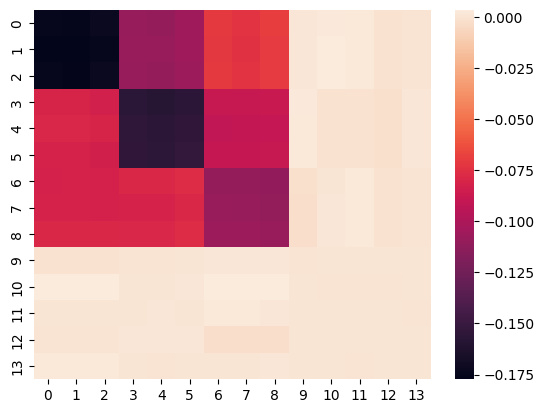

In [7]:
sns.heatmap(st_svd.adjacency)

In [8]:
clustering = ClusteringCPQR(st_svd.adjacency, k=3)

In [9]:
clustering.vkT.shape

(3, 14)

In [10]:
clustering.U.shape

(3, 3)

In [11]:
clustering.transformed.shape

(3, 14)

In [12]:
fig = fpl.Figure(cameras="3d", controller_types="orbit")

fig[0, 0].add_scatter(clustering.vkT.T, colors="r", name="vkT", sizes=15)
fig[0, 0].add_scatter(clustering.U, colors="b", name="U", sizes=15)
fig[0, 0].add_scatter(clustering.transformed.T, colors="g", name="transform", sizes=15)

fig[0, 0].axes.intersection = (0, 0, 0)
fig.show()

RFBOutputContext()

/mnt/home/kkolar/repos/pygfx/pygfx/objects/_ruler.py:245: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/mnt/home/kkolar/repos/pygfx/pygfx/objects/_ruler.py:245: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/mnt/home/kkolar/repos/pygfx/pygfx/objects/_ruler.py:257: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size
/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [13]:
from ipywidgets import IntSlider, Button, VBox

In [24]:
slider_n_components = IntSlider(min=2, max=50, step=1, description="n_components")
slider_n_pixels = IntSlider(min=1, max=15, step=1, description="pixels per component")
slider_noise = IntSlider(min=0, max=30, step=1, description="noise sigma")
slider_n_bg_pixels = IntSlider(min=0, max=100, step=1, description="n background pixels")
slider_k = IntSlider(min=2, max=50, step=1, description="k")
button = Button(description="Update")

iw_movie = fpl.ImageWidget(movie, figure_kwargs={"size": (1200, 600)})
iw_movie.figure.show(maintain_aspect=False)

iw = fpl.ImageWidget(
    [clustering.vkT, clustering.U, clustering.transformed], 
    names=["vk.T", "U", "transformed"], 
    figure_shape=(1, 3),
    figure_kwargs={"controller_ids": [[0, 1, 2]], "size": (1200, 350)},
)
iw.cmap = ["bwr", "bwr", "viridis"]
iw.figure.show(maintain_aspect=False)

def update_movie(*args):
    movie = generate_data(
        n_timepoints=1_000, 
        n_components=slider_n_components.value,
        noise=slider_noise.value,
        n_pixels=slider_n_pixels.value,
        n_pixels_bg=slider_n_bg_pixels.value,
    )

    global st_svd
    
    st_svd = SpaceTimeSVD(movie, w=16)
    st_svd.compute()

    iw_movie.set_data(movie)
    iw_movie.figure[0, 0].auto_scale(maintain_aspect=False)

def update_clustering(*args):
    global st_svd
    
    clustering = ClusteringCPQR(st_svd.adjacency, k=slider_k.value)

    iw.set_data([clustering.vkT, clustering.U, clustering.transformed])
    
    for subplot in iw.figure:
        subplot.auto_scale(maintain_aspect=False)

    iw.cmap = ["bwr", "bwr", "viridis"]

sliders = VBox([slider_n_components, slider_n_pixels, slider_noise, slider_n_bg_pixels, button])

button.on_click(update_movie)

button_clustering = Button(description="Update k")
button_clustering.on_click(update_clustering)

VBox([sliders, iw_movie.show(), slider_k, button_clustering, iw.show()])

RFBOutputContext()

RFBOutputContext()

In [27]:
iw.cmap = ["bwr", "bwr", "viridis"]